# Independent kidney cohort: length matching at 100k fragments (Fig. 6e)

Reads tables from `../data/` and writes figures to `../output/`.
Source analysis: `../../NOTEBOOK_PROVENANCE.tsv`.

Frozen, Cristiano-trained models applied without retraining to the independent
kidney cohort (n = 12: 6 kidney cancer, 6 healthy) at 100,000 fragments per
sample, before and after fragment-length matching. Bars are the mean ROC AUC
over 10 with-replacement fragment bags; error bars are the paired
class-stratified hierarchical-bootstrap 95% CI (2,000 iterations, seed
20260901). Blue, original bags; orange, bags resampled to the shared,
label-free pooled length target. The fragment-length model uses per-sample
length percentiles, so its AUC is 0.5 by construction after matching.

This is the Fig. 6e variant with three extra bar pairs: frozen Bin, Bin + Length
and Bin + DELFI at ~100 kb (30,000 genome-wide bins). Drawn with the source
script's own code and rcParams
(`output/cfdna/cfdna_internal_cohort_subsampling/plot_fig6e.py --with-bin-fusions`).

Panel:
- `cfdna_kidney_length_matching_bin_fusions`

In [1]:
from pathlib import Path
import sys

# Self-contained: works when run from notebook/, from the modality folder, or from the repo root.
nb_dir = Path.cwd()
if (nb_dir / "data").exists() and (nb_dir / "output").exists():
    MOD_DIR = nb_dir
elif (nb_dir.parent / "data").exists():
    MOD_DIR = nb_dir.parent
else:
    MOD_DIR = nb_dir
DATA = MOD_DIR / "data"
OUT = MOD_DIR / "output"
OUT.mkdir(exist_ok=True)

# Locate the shared style helper (src/leaf1figures) by walking up.
_p = nb_dir
while _p != _p.parent and not (_p / "src" / "leaf1figures").exists():
    _p = _p.parent
sys.path.insert(0, str(_p / "src"))

from leaf1figures.style import OKABE_ITO, savefig, set_paper_style
set_paper_style()
print("DATA:", DATA.relative_to(_p))
print("OUT :", OUT.relative_to(_p))

DATA: cfdna/data
OUT : cfdna/output


saved: cfdna/output/cfdna_kidney_length_matching_bin_fusions.pdf
saved: cfdna/output/cfdna_kidney_length_matching_bin_fusions.png
saved: cfdna/output/cfdna_kidney_length_matching_bin_fusions.svg
saved: cfdna/output/cfdna_kidney_length_matching_bin_fusions.tsv


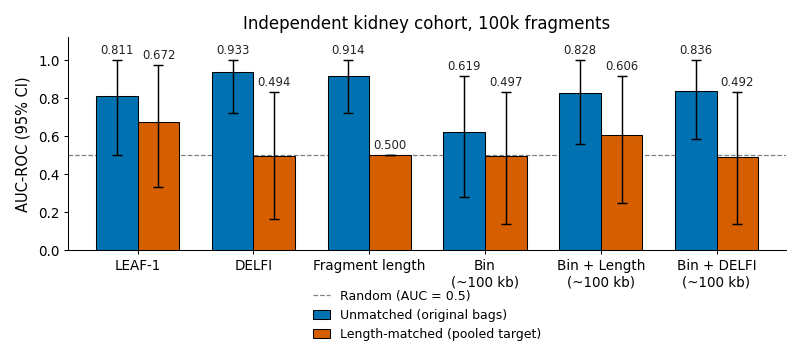

           model  variant  mean_roc_auc  ci95_low  ci95_high
           leaf1 original         0.811     0.500      1.000
           leaf1   pooled         0.672     0.333      0.972
           delfi original         0.933     0.722      1.000
           delfi   pooled         0.494     0.167      0.833
          length original         0.914     0.722      1.000
          length   pooled         0.500     0.500      0.500
genome_bin_30000 original         0.619     0.278      0.917
genome_bin_30000   pooled         0.497     0.139      0.833
bin_length_30000 original         0.828     0.556      1.000
bin_length_30000   pooled         0.606     0.250      0.917
 bin_delfi_30000 original         0.836     0.583      1.000
 bin_delfi_30000   pooled         0.492     0.139      0.833


In [2]:
# ── Figure, as plot_fig6e.py --with-bin-fusions ───────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DEPTH = 100_000
MODELS = ("leaf1", "delfi", "length", "genome_bin_30000", "bin_length_30000", "bin_delfi_30000")
MODEL_LABELS = {"leaf1": "LEAF-1", "delfi": "DELFI", "length": "Fragment length",
                "genome_bin_30000": "Bin\n(~100 kb)",
                "bin_length_30000": "Bin + Length\n(~100 kb)",
                "bin_delfi_30000": "Bin + DELFI\n(~100 kb)"}
VARIANTS = (("original", "Unmatched (original bags)", "#0072B2"),
            ("pooled", "Length-matched (pooled target)", "#D55E00"))
FIG6E_RC = {
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "DejaVu Sans", "Helvetica", "Liberation Sans"],
    "font.size": 7, "axes.titlesize": 8, "axes.labelsize": 7,
    "xtick.labelsize": 6.5, "ytick.labelsize": 6.5, "legend.fontsize": 6,
    "axes.linewidth": 0.5, "xtick.major.width": 0.5, "ytick.major.width": 0.5,
    "figure.dpi": 150, "savefig.dpi": 600, "savefig.bbox": "tight",
    "pdf.fonttype": 42, "ps.fonttype": 42, "svg.fonttype": "none",
    "axes.spines.top": False, "axes.spines.right": False,
}

t = pd.read_csv(DATA / "cfdna_kidney_length_matching_depth_summary.csv", float_precision="round_trip")
sub = t[(t.sample_size == DEPTH) & t.variant.isin([v for v, _, _ in VARIANTS])
        & t.model.isin(MODELS)].copy()
assert len(sub) == len(VARIANTS) * len(MODELS) and (sub.n_repeats == 10).all()
assert ((sub.ci95_low <= sub.mean_roc_auc + 1e-9) & (sub.ci95_high >= sub.mean_roc_auc - 1e-9)).all()
sub["model_label"] = sub.model.map(MODEL_LABELS)
sub["variant_label"] = sub.variant.map({v: lab for v, lab, _ in VARIANTS})
sub["model_order"] = sub.model.map({m: i for i, m in enumerate(MODELS)})
sub["variant_order"] = sub.variant.map({v: i for i, (v, _, _) in enumerate(VARIANTS)})
table = sub.sort_values(["model_order", "variant_order"]).reset_index(drop=True)

with plt.rc_context(FIG6E_RC):
    fig, ax = plt.subplots(figsize=(3.1 + 0.75 * (len(MODELS) - 3), 2.5))
    x = np.arange(len(MODELS)); width = 0.36
    for (variant, label, color), offset in zip(VARIANTS, (-width / 2, width / 2)):
        rows = table[table.variant == variant].sort_values("model_order")
        auc = rows.mean_roc_auc.to_numpy()
        lower = auc - rows.ci95_low.to_numpy(); upper = rows.ci95_high.to_numpy() - auc
        bars = ax.bar(x + offset, auc, width=width, color=color, edgecolor="black", linewidth=0.5,
                      yerr=[np.clip(lower, 0, None), np.clip(upper, 0, None)], capsize=2.2,
                      error_kw=dict(elinewidth=0.7, ecolor="black", capthick=0.7), label=label, zorder=3)
        for bar, value, high in zip(bars, auc, rows.ci95_high.to_numpy()):
            ax.text(bar.get_x() + bar.get_width() / 2, high + 0.018, f"{value:.3f}",
                    ha="center", va="bottom", fontsize=5.6, color="#222222")
    ax.axhline(0.5, color="0.5", linestyle="--", linewidth=0.6, zorder=1, label="Random (AUC = 0.5)")
    ax.set_xticks(x); ax.set_xticklabels([MODEL_LABELS[m] for m in MODELS])
    ax.set_xlim(-0.6, len(MODELS) - 0.4); ax.set_ylim(0.0, 1.12)
    ax.set_yticks([0.0, 0.2, 0.4, 0.6, 0.8, 1.0])
    ax.set_ylabel("AUC-ROC (95% CI)")
    ax.set_title(f"Independent kidney cohort, {DEPTH // 1000:,}k fragments", pad=4)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=1, frameon=False,
              handlelength=1.4, borderaxespad=0.0)
    ax.tick_params(axis="both", which="major", length=2, pad=2)
    fig.tight_layout()
    out = table[["model", "model_label", "variant", "variant_label", "sample_size", "n_repeats",
                 "mean_roc_auc", "ci95_low", "ci95_high", "bootstrap_iterations",
                 "bootstrap_seed", "ci_method"]]
    savefig(fig, OUT, "cfdna_kidney_length_matching_bin_fusions", data=out)
    plt.show()
print(out[["model", "variant", "mean_roc_auc", "ci95_low", "ci95_high"]].round(3).to_string(index=False))